# Avaliação Prática: Fusão de Imagens (Image Blending) com Pirâmides Laplacianas

**Disciplina:** Visão Computacional / Processamento Digital de Imagens  
**Formato:** Em duplas  
**Integrantes da Dupla:**  
1. *César Oliveira de Lima Filho - 202502200*
2. *Nome Completo 2 - Matrícula*

---

## Contexto do Problema: O Desafio do "Maçanja" (Orapple)

Na edição profissional de imagens, simplesmente recortar uma metade de uma foto e colar sobre outra cria uma borda artificial e abrupta devido às diferenças de iluminação, cor e textura. 

Para resolver isso, Burt e Adelson (1983) propuseram o uso de **Pirâmides Laplacianas**. A técnica consiste em decompor as imagens em diferentes bandas de frequência espacial (das texturas mais finas às variações suaves de iluminação), misturar cada nível usando uma máscara suavizada e reconstruir a imagem final. O exemplo clássico da literatura é a fusão perfeita entre uma maçã e uma laranja (o famoso *Orapple*).

### Setup Inicial e Geração de Imagens de Teste
Execute a célula abaixo para importar as bibliotecas e gerar o ambiente de teste sintético ($512 \times 512$ pixels).

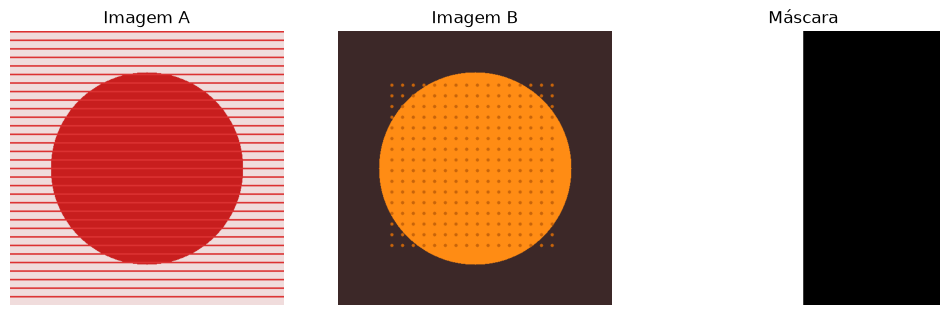

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def gerar_imagens_teste():
    """Gera duas imagens sintéticas 512x512 caso a dupla não tenha arquivos locais."""
    img_A = np.zeros((512, 512, 3), dtype=np.uint8)
    img_B = np.zeros((512, 512, 3), dtype=np.uint8)
    
    # Imagem A: Fundo claro com círculo vermelho (simulando maçã) e textura de linhas
    img_A[:] = (220, 220, 240)
    cv2.circle(img_A, (256, 256), 180, (30, 30, 200), -1)
    for i in range(0, 512, 16):
        cv2.line(img_A, (0, i), (512, i), (50, 50, 220), 2)

    # Imagem B: Fundo escuro com círculo laranja (simulando laranja) e textura pontilhada
    img_B[:] = (40, 40, 60)
    cv2.circle(img_B, (256, 256), 180, (20, 140, 255), -1)
    for y in range(100, 412, 20):
        for x in range(100, 412, 20):
            cv2.circle(img_B, (x, y), 3, (10, 100, 200), -1)
            
    return img_A, img_B

A, B = gerar_imagens_teste()

# Máscara binária: metade esquerda branca (1.0), metade direita preta (0.0)
mascara = np.zeros((512, 512, 3), dtype=np.float32)
mascara[:, :256] = 1.0

# Visualizando as entradas
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.title("Imagem A"); plt.imshow(cv2.cvtColor(A, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.subplot(1, 3, 2); plt.title("Imagem B"); plt.imshow(cv2.cvtColor(B, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.subplot(1, 3, 3); plt.title("Máscara"); plt.imshow(mascara); plt.axis("off")
plt.show()

---
### Questão 1: Construção da Pirâmide Gaussiana (2,5 pontos)

Uma Pirâmide Gaussiana é uma sequência de imagens onde cada nível subsequente é suavizado por um filtro Gaussiano e reduzido pela metade em largura e altura (subamostragem). 

**Tarefa:** Complete a função `gerar_piramide_gaussiana(imagem, niveis)` abaixo. A função deve receber uma imagem (convertida para `float32`) e o número de níveis desejado, retornando uma lista contendo a imagem original no índice `0` e as versões reduzidas nos índices seguintes.

*Dica:* Utilize a função `cv2.pyrDown()`.

In [ ]:
def gerar_piramide_gaussiana(imagem, niveis):
    """
    Constrói uma pirâmide Gaussiana com o número especificado de níveis.
    
    Parâmetros:
        imagem (np.ndarray): Imagem de entrada (dtype float32).
        niveis (int): Quantidade de níveis da pirâmide (incluindo a base).
        
    Retorno:
        list: Lista de arrays NumPy representando cada nível da pirâmide.
    """
    piramide = [imagem.astype(np.float32)]
    
    # --- INÍCIO DO CÓDIGO DA DUPLA ---
    
    # TODO: Iterar (niveis - 1) vezes, aplicando cv2.pyrDown no último elemento 
    # adicionado à lista e anexando o resultado na pirâmide.
    
    pass
    
    # --- FIM DO CÓDIGO DA DUPLA ---
    
    return piramide

---
### Questão 2: Construção da Pirâmide Laplaciana / Diferença de Gaussianas (3,5 pontos)

A Pirâmide Laplaciana armazena os detalhes (altas frequências) perdidos entre um nível da Pirâmide Gaussiana e o seu nível imediatamente superior (mais reduzido). Matematicamente, cada nível $L_i$ é obtido pela diferença:

$$L_i = G_i - \text{Expand}(G_{i+1})$$

O último nível da Pirâmide Laplaciana (o topo, de menor resolução) é simplesmente o último nível da Pirâmide Gaussiana ($L_n = G_n$), pois não há nível acima dele para subtrair.

**Tarefa:** Complete a função `gerar_piramide_laplaciana(piramide_gaussiana)` usando `cv2.pyrUp()` para expandir o nível $G_{i+1}$.

*Atenção:* Caso as dimensões após o `pyrUp` difiram por 1 pixel devido a tamanhos ímpares, garanta que a imagem expandida tenha exatamente o mesmo `shape` de $G_i$ antes de subtrair.

In [ ]:
def gerar_piramide_laplaciana(piramide_gaussiana):
    """
    Constrói uma pirâmide Laplaciana a partir de uma pirâmide Gaussiana.
    
    Parâmetros:
        piramide_gaussiana (list): Lista gerada pela Questão 1.
        
    Retorno:
        list: Lista contendo os níveis Laplacianas (do mais fino ao topo Gaussiano).
    """
    niveis = len(piramide_gaussiana)
    piramide_lap = []
    
    # --- INÍCIO DO CÓDIGO DA DUPLA ---
    
    # TODO 1: Percorrer do nível 0 até (niveis - 2).
    # Para cada nível i:
    #   a) Expandir o nível (i + 1) usando cv2.pyrUp()
    #   b) Garantir que as dimensões coincidam com piramide_gaussiana[i]
    #   c) Calcular a diferença (G_i - G_{i+1}_expandido) e adicionar à piramide_lap
    
    # TODO 2: Adicionar o último nível da pirâmide Gaussiana ao final de piramide_lap
    
    pass

    # --- FIM DO CÓDIGO DA DUPLA ---
    
    return piramide_lap

---
### Questão 3: Fusão por Pirâmides e Reconstrução (4,0 pontos)

Para realizar o *blending* perfeito:
1. Construa as pirâmides Laplacianas $LA$ e $LB$ para as imagens $A$ e $B$.
2. Construa uma **Pirâmide Gaussiana** $GM$ para a `mascara` (isso garante que transições suaves ocorram nas baixas frequências e transições nítidas nas altas frequências).
3. Para cada nível $i$, combine os Laplacianas usando a máscara correspondente:
   $$LS_i = GM_i \cdot LA_i + (1.0 - GM_i) \cdot LB_i$$
4. **Reconstrução:** Comece pelo topo da pirâmide combinada ($LS_{n}$), expanda-o com `cv2.pyrUp()` e some ao nível inferior $LS_{n-1}$, repetindo o processo até chegar à resolução original (nível 0).

**Tarefa:** Complete as funções `combinar_piramides` e `reconstruir_imagem` abaixo.

In [ ]:
def combinar_piramides(lap_A, lap_B, gauss_mascara):
    """
    Combina duas pirâmides Laplacianas usando os níveis de uma pirâmide Gaussiana da máscara.
    """
    piramide_combinada = []
    
    # --- INÍCIO DO CÓDIGO DA DUPLA (PARTE A) ---
    
    # TODO: Iterar simultaneamente por lap_A, lap_B e gauss_mascara
    # Aplicar a fórmula: LS_i = GM_i * LA_i + (1.0 - GM_i) * LB_i
    # Adicionar LS_i à piramide_combinada
    
    pass

    # --- FIM DO CÓDIGO DA DUPLA (PARTE A) ---
    
    return piramide_combinada


def reconstruir_imagem(piramide_laplaciana):
    """
    Reconstrói a imagem final colapsando a pirâmide Laplaciana do topo até a base.
    """
    # --- INÍCIO DO CÓDIGO DA DUPLA (PARTE B) ---
    
    # TODO 1: Iniciar a imagem reconstruída com o topo da pirâmide (último elemento)
    
    # TODO 2: Iterar de trás para frente, do penúltimo nível até o índice 0:
    #   a) Expandir a imagem reconstruída atual com cv2.pyrUp()
    #   b) Ajustar o tamanho se necessário e somar com o nível atual da pirâmide
    
    # TODO 3: Fazer o clip dos valores entre [0, 255] com np.clip() e converter para np.uint8
    
    pass

    # --- FIM DO CÓDIGO DA DUPLA (PARTE B) ---

### Pipeline de Execução e Comparação Visual
Execute a célula abaixo para testar suas funções e comparar a colagem direta com o *blending* por pirâmide Laplaciana.

In [ ]:
NIVEIS = 6

# 1. Gerar pirâmides Gaussianas
gp_A = gerar_piramide_gaussiana(A, NIVEIS)
gp_B = gerar_piramide_gaussiana(B, NIVEIS)
gp_M = gerar_piramide_gaussiana(mascara, NIVEIS)

# 2. Gerar pirâmides Laplacianas
lp_A = gerar_piramide_laplaciana(gp_A)
lp_B = gerar_piramide_laplaciana(gp_B)

# 3. Combinar e reconstruir
lp_combinada = combinar_piramides(lp_A, lp_B, gp_M)
resultado_blending = reconstruir_imagem(lp_combinada)

# 4. Comparação: Colagem Direta vs. Pirâmide Laplaciana
colagem_direta = (mascara * A + (1.0 - mascara) * B).astype(np.uint8)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Colagem Direta (Sem Pirâmide)")
plt.imshow(cv2.cvtColor(colagem_direta, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Blending com Pirâmide Laplaciana")
plt.imshow(cv2.cvtColor(resultado_blending, cv2.COLOR_BGR2RGB))
plt.axis("off")

plt.tight_layout()
plt.show()

---
### Teste Extra: Imagens Reais e Questão Bônus (1,0 ponto)

1. Na célula de código abaixo, carregue duas imagens reais de sua escolha (redimensionadas para $512 \times 512$) e exiba o resultado da fusão.
2. **Pergunta Conceitual (Bônus):** Responda na célula de texto seguinte: *O que acontece visualmente na linha de junção se alterarmos a variável `NIVEIS` de `6` para `2`? Por que isso ocorre em termos de frequências espaciais?*

In [ ]:
# Espaço para o teste da dupla com imagens reais
# img1 = cv2.resize(cv2.imread('imagem1.jpg'), (512, 512))
# img2 = cv2.resize(cv2.imread('imagem2.jpg'), (512, 512))


**Resposta da Dupla (Questão Bônus):**  
*Escreva sua resposta aqui...*